# Taller 03 - Ciencia de Datos

## Análisis de Redes y Sistemas de Recomendación

**Maestría en Ciencia de Datos**

En este taller se aplicarán técnicas de análisis de redes y sistemas de recomendación utilizando el conjunto de datos **MovieLens 100K**.

El trabajo se divide en dos partes principales:

- Análisis de redes con NetworkX.
- Sistemas de recomendación con Surprise.

Se analizarán las interacciones entre usuarios y películas, la centralidad de los nodos, comunidades dentro de la red y modelos de recomendación basados en filtrado colaborativo.

# Parte 1 - Análisis de Redes con NetworkX

En esta sección se construirá un grafo bipartito a partir de las interacciones entre usuarios y películas del conjunto de datos MovieLens 100K.

Se analizarán:

- Usuarios más activos.
- Películas más populares.
- Centralidad de grado.
- Coeficiente de agrupamiento.
- Detección de comunidades.
- Visualización de la red.

## 1.1 Importación de librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

print("Librerías cargadas correctamente")

Librerías cargadas correctamente


## 1.2 Carga del conjunto de datos MovieLens 100K

Se cargará el archivo de calificaciones del conjunto de datos MovieLens 100K.

Este archivo contiene las interacciones entre usuarios y películas, incluyendo el identificador del usuario, identificador de la película, calificación otorgada y marca de tiempo.

In [3]:
columnas = ["user_id", "movie_id", "rating", "timestamp"]

ratings = pd.read_csv(
    "ml-100k/u.data",
    sep="\t",
    names=columnas
)

print("Dataset cargado correctamente")
print("Dimensiones:", ratings.shape)

ratings.head()

Dataset cargado correctamente
Dimensiones: (100000, 4)


,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


## 1.3 Exploración inicial del dataset

Antes de construir el grafo, se revisa la estructura general del conjunto de datos para conocer el número de usuarios, películas, calificaciones y posibles valores faltantes.

In [4]:
ratings.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   user_id    100000 non-null  int64
 1   movie_id   100000 non-null  int64
 2   rating     100000 non-null  int64
 3   timestamp  100000 non-null  int64
dtypes: int64(4)
memory usage: 3.1 MB


In [5]:
print("Número de usuarios:", ratings["user_id"].nunique())
print("Número de películas:", ratings["movie_id"].nunique())
print("Número de calificaciones:", len(ratings))

Número de usuarios: 943
Número de películas: 1682
Número de calificaciones: 100000


In [6]:
ratings.isnull().sum()

user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64

In [7]:
ratings["rating"].describe()

count    100000.000000
mean          3.529860
std           1.125674
min           1.000000
25%           3.000000
50%           4.000000
75%           4.000000
max           5.000000
Name: rating, dtype: float64

## 1.4 Carga de información de las películas

Se carga el archivo `u.item` del conjunto de datos MovieLens 100K para relacionar el identificador de cada película con su título.

Esto permitirá presentar los resultados del análisis de redes utilizando nombres de películas en lugar de únicamente identificadores numéricos.

In [8]:
movies = pd.read_csv(
    "ml-100k/u.item",
    sep="|",
    header=None,
    encoding="latin-1"
)

movies = movies[[0, 1]]

movies.columns = [
    "movie_id",
    "title"
]

print("Información de películas cargada correctamente")
print("Cantidad de películas:", len(movies))

movies.head()

Información de películas cargada correctamente
Cantidad de películas: 1682


,movie_id,title
0,1,Toy Story (1995)
1,2,GoldenEye (1995)
2,3,Four Rooms (1995)
3,4,Get Shorty (1995)
4,5,Copycat (1995)


## 1.5 Unión de calificaciones y películas

Se integran las calificaciones de los usuarios con la información de las películas utilizando la variable `movie_id`.

Esto permitirá trabajar con los títulos reales de las películas durante el análisis de la red.

In [9]:
datos = ratings.merge(
    movies,
    on="movie_id",
    how="left"
)

print("Datos unidos correctamente")
print("Dimensiones:", datos.shape)

datos.head()

Datos unidos correctamente
Dimensiones: (100000, 5)


,user_id,movie_id,rating,timestamp,title
0,196,242,3,881250949,Kolya (1996)
1,186,302,3,891717742,L.A. Confidential (1997)
2,22,377,1,878887116,Heavyweights (1994)
3,244,51,2,880606923,Legends of the Fall (1994)
4,166,346,1,886397596,Jackie Brown (1997)


In [10]:
print("Películas sin título:", datos["title"].isnull().sum())

Películas sin título: 0


## 1.6 Construcción del grafo bipartito

Se construye un grafo bipartito en el que existen dos tipos de nodos:

- Usuarios.
- Películas.

Cada usuario se conecta con las películas que ha calificado.

La calificación otorgada se almacena como atributo de la arista.

In [11]:
G = nx.Graph()

# Agregar nodos de usuarios
usuarios = datos["user_id"].unique()

for usuario in usuarios:
    G.add_node(
        f"U_{usuario}",
        bipartite="usuario"
    )

# Agregar nodos de películas
peliculas = datos[["movie_id", "title"]].drop_duplicates()

for _, fila in peliculas.iterrows():
    G.add_node(
        f"M_{fila['movie_id']}",
        bipartite="pelicula",
        title=fila["title"]
    )

print("Nodos agregados correctamente")
print("Número total de nodos:", G.number_of_nodes())

Nodos agregados correctamente
Número total de nodos: 2625


In [12]:
for _, fila in datos.iterrows():
    G.add_edge(
        f"U_{fila['user_id']}",
        f"M_{fila['movie_id']}",
        rating=fila["rating"]
    )

print("Grafo construido correctamente")
print("Número de nodos:", G.number_of_nodes())
print("Número de aristas:", G.number_of_edges())

Grafo construido correctamente
Número de nodos: 2625
Número de aristas: 100000


## 1.7 Identificación de los usuarios más activos

Se calcula el grado de los nodos correspondientes a usuarios.

En este grafo bipartito, el grado de un usuario representa la cantidad de películas que ha calificado.

Por lo tanto, los usuarios con mayor grado son los usuarios más activos dentro de la red.

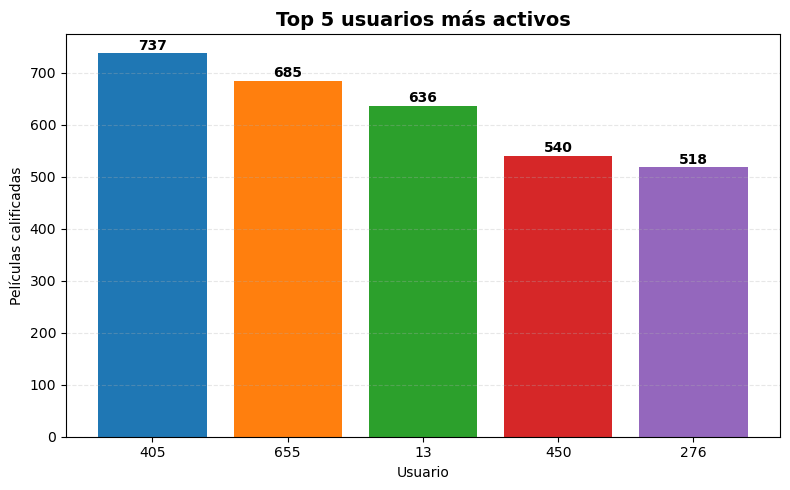

In [16]:
# Colores diferentes para cada barra
colores = plt.cm.tab10.colors

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    top_5_usuarios["user_id"].astype(str),
    top_5_usuarios["peliculas_calificadas"],
    color=colores[:5]
)

ax.set_title(
    "Top 5 usuarios más activos",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Usuario")
ax.set_ylabel("Películas calificadas")

# Agregar valor sobre cada barra
for barra in barras:
    valor = barra.get_height()
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 1,
        f"{int(valor)}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()

# Guardar imagen
plt.savefig(
    "top_5_usuarios_activos.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 1.8 Identificación de las películas más centrales

Se calcula el grado de los nodos correspondientes a películas.

En el grafo bipartito, el grado de una película representa la cantidad de usuarios que la han calificado.

Por lo tanto, las películas con mayor grado pueden interpretarse como las más populares o centrales dentro de la red.

### 1.8.1 Películas con mayor número de calificaciones

En el grafo bipartito, el grado de una película representa la cantidad de usuarios que la han calificado.

Las películas con mayor grado pueden interpretarse como las de mayor popularidad dentro de la red.

In [17]:
peliculas_centrales = []

for _, fila in peliculas.iterrows():
    nodo = f"M_{fila['movie_id']}"
    grado = G.degree(nodo)

    peliculas_centrales.append({
        "movie_id": fila["movie_id"],
        "title": fila["title"],
        "usuarios_que_calificaron": grado
    })

peliculas_centrales = pd.DataFrame(peliculas_centrales)

top_10_peliculas = (
    peliculas_centrales
    .sort_values(
        "usuarios_que_calificaron",
        ascending=False
    )
    .head(10)
)

top_10_peliculas

,movie_id,title,usuarios_que_calificaron
357,50,Star Wars (1977),583
157,258,Contact (1997),509
49,100,Fargo (1996),508
52,181,Return of the Jedi (1983),507
95,294,Liar Liar (1997),485
289,286,"English Patient, The (1996)",481
60,288,Scream (1996),478
24,1,Toy Story (1995),452
652,300,Air Force One (1997),431
403,121,Independence Day (ID4) (1996),429


### 1.8.2 Centralidad de grado de las películas

Se calcula la centralidad de grado normalizada utilizando NetworkX.

Esta métrica permite comparar la importancia relativa de las películas dentro de la estructura completa de la red.

In [19]:
centralidad_grado = nx.degree_centrality(G)

centralidad_peliculas = []

for _, fila in peliculas.iterrows():
    nodo = f"M_{fila['movie_id']}"

    centralidad_peliculas.append({
        "movie_id": fila["movie_id"],
        "title": fila["title"],
        "centralidad_grado": centralidad_grado[nodo]
    })

centralidad_peliculas = pd.DataFrame(
    centralidad_peliculas
)

top_10_centralidad = (
    centralidad_peliculas
    .sort_values(
        "centralidad_grado",
        ascending=False
    )
    .head(10)
)

top_10_centralidad

,movie_id,title,centralidad_grado
357,50,Star Wars (1977),0.222180
157,258,Contact (1997),0.193979
49,100,Fargo (1996),0.193598
52,181,Return of the Jedi (1983),0.193216
95,294,Liar Liar (1997),0.184832
289,286,"English Patient, The (1996)",0.183308
60,288,Scream (1996),0.182165
24,1,Toy Story (1995),0.172256
652,300,Air Force One (1997),0.164253
403,121,Independence Day (ID4) (1996),0.163491


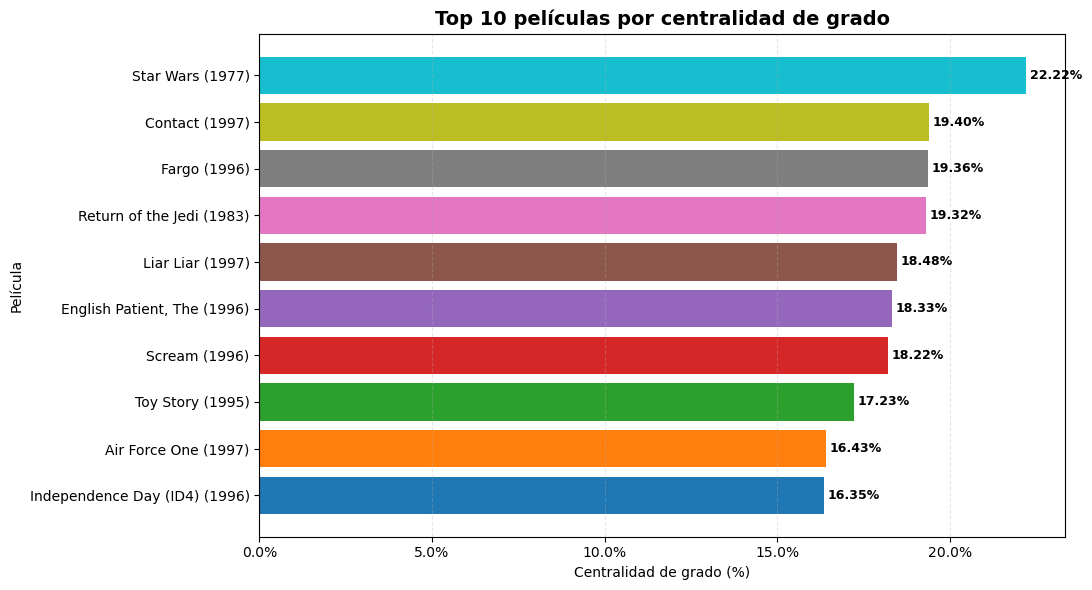

In [24]:
colores = plt.cm.tab10.colors

datos_centralidad = top_10_centralidad.sort_values(
    "centralidad_grado"
)

fig, ax = plt.subplots(figsize=(11, 6))

barras = ax.barh(
    datos_centralidad["title"],
    datos_centralidad["centralidad_grado"],
    color=colores
)

ax.set_title(
    "Top 10 películas por centralidad de grado",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Centralidad de grado (%)")
ax.set_ylabel("Película")

for barra in barras:
    valor = barra.get_width()

    ax.text(
        valor + 0.001,
        barra.get_y() + barra.get_height() / 2,
        f"{valor * 100:.2f}%",
        va="center",
        fontsize=9,
        fontweight="bold"
    )

ax.grid(axis="x", linestyle="--", alpha=0.3)
from matplotlib.ticker import PercentFormatter

ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))

plt.tight_layout()

fig.savefig(
    "centralidad_grado_peliculas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 1.9 Coeficiente de agrupamiento bipartito

Debido a que la red está formada por dos tipos de nodos, usuarios y películas, se utiliza una medida de agrupamiento específica para grafos bipartitos.

Esta métrica permite analizar qué tan similares son las conexiones de un nodo respecto a otros nodos del mismo tipo.

Un valor más alto indica que el nodo comparte una mayor proporción de conexiones con otros nodos de la red.

In [25]:
from networkx.algorithms import bipartite

clustering_bipartito = bipartite.clustering(G)

print("Coeficiente de agrupamiento calculado correctamente")
print("Cantidad de nodos analizados:", len(clustering_bipartito))

Coeficiente de agrupamiento calculado correctamente
Cantidad de nodos analizados: 2625


In [26]:
promedio_clustering = np.mean(
    list(clustering_bipartito.values())
)

print(
    f"Coeficiente de agrupamiento promedio: "
    f"{promedio_clustering:.4f}"
)

Coeficiente de agrupamiento promedio: 0.0715


In [27]:
clustering_usuarios = {
    nodo: valor
    for nodo, valor in clustering_bipartito.items()
    if nodo.startswith("U_")
}

clustering_peliculas = {
    nodo: valor
    for nodo, valor in clustering_bipartito.items()
    if nodo.startswith("M_")
}

print(
    "Promedio usuarios:",
    round(np.mean(list(clustering_usuarios.values())), 4)
)

print(
    "Promedio películas:",
    round(np.mean(list(clustering_peliculas.values())), 4)
)

Promedio usuarios: 0.0888
Promedio películas: 0.0618


In [28]:
clustering_peliculas_df = pd.DataFrame(
    [
        {
            "movie_id": int(nodo.replace("M_", "")),
            "clustering": valor
        }
        for nodo, valor in clustering_peliculas.items()
    ]
)

clustering_peliculas_df = clustering_peliculas_df.merge(
    movies,
    on="movie_id",
    how="left"
)

top_10_clustering = (
    clustering_peliculas_df
    .sort_values(
        "clustering",
        ascending=False
    )
    .head(10)
)

top_10_clustering[
    ["movie_id", "title", "clustering"]
]

,movie_id,title,clustering
1669,1667,"Next Step, The (1995)",0.116982
1661,1665,"Brother's Kiss, A (1997)",0.116982
1654,1668,Wedding Bell Blues (1996),0.116982
1663,1670,Tainted (1998),0.116982
1612,1669,MURDER and murder (1996),0.116982
1634,1666,Ripe (1996),0.116982
1617,1663,Nothing Personal (1995),0.116982
114,385,True Lies (1994),0.109383
82,403,Batman (1989),0.108458
528,393,Mrs. Doubtfire (1993),0.107951


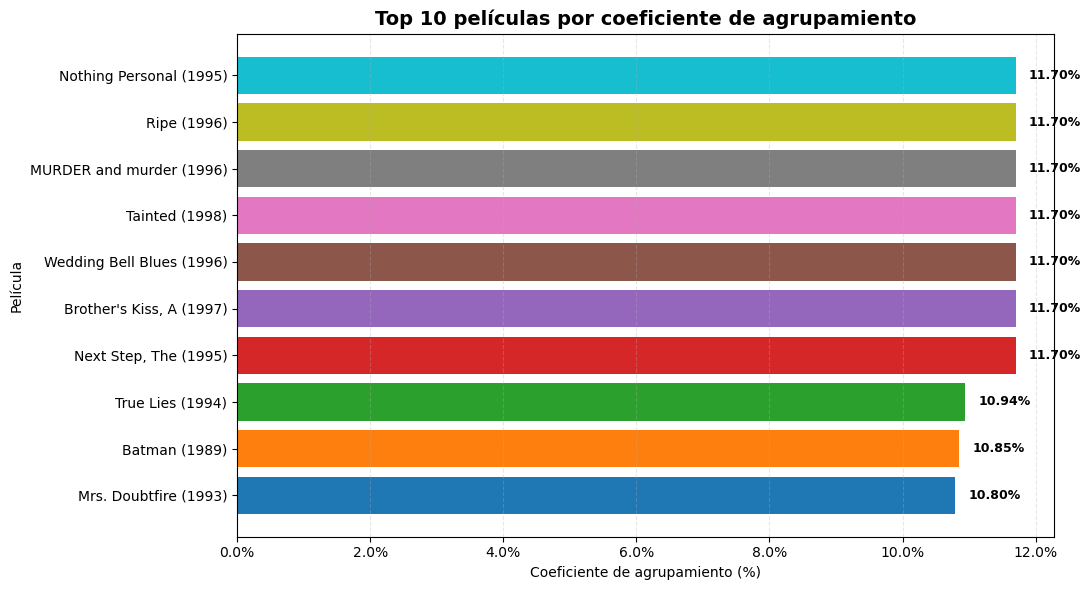

In [30]:
from matplotlib.ticker import PercentFormatter

datos_clustering = (
    top_10_clustering
    .sort_values("clustering")
)

colores = plt.cm.tab10.colors

fig, ax = plt.subplots(figsize=(11, 6))

barras = ax.barh(
    datos_clustering["title"],
    datos_clustering["clustering"],
    color=colores
)

ax.set_title(
    "Top 10 películas por coeficiente de agrupamiento",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Coeficiente de agrupamiento (%)")
ax.set_ylabel("Película")

# Agregar etiquetas en porcentaje
for barra in barras:
    valor = barra.get_width()

    ax.text(
        valor + 0.002,
        barra.get_y() + barra.get_height() / 2,
        f"{valor * 100:.2f}%",
        va="center",
        fontsize=9,
        fontweight="bold"
    )

# Mostrar el eje X como porcentaje
ax.xaxis.set_major_formatter(
    PercentFormatter(xmax=1)
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

# Guardar imagen
fig.savefig(
    "coeficiente_agrupamiento_peliculas.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 1.10 Detección de comunidades

Se aplica el algoritmo de Girvan-Newman para identificar comunidades dentro de la red.

Este método detecta grupos de nodos que presentan una mayor densidad de conexiones internas, permitiendo identificar conjuntos de usuarios y películas relacionados entre sí.

### Justificación del uso de una subred

El grafo completo contiene 2.625 nodos y 100.000 aristas.

Debido al costo computacional del algoritmo Girvan-Newman, la detección de comunidades se realizó sobre una subred representativa, lo que permite aplicar el método de forma eficiente y visualizar con claridad la estructura resultante.

El análisis sobre la subred mantiene la lógica usuario-película del conjunto original y permite cumplir con el objetivo de explorar la formación de comunidades dentro de la red.

### 1.10.1 Construcción de una subred para detección de comunidades

### 1.10.1 Construcción de una subred para detección de comunidades

Debido al tamaño del grafo completo, se construye una subred representativa utilizando los usuarios más activos y las películas que han calificado.

Esto permite aplicar el algoritmo de Girvan-Newman de manera eficiente sin perder la estructura usuario-película del análisis.

In [31]:
top_usuarios_subred = (
    usuarios_activos
    .sort_values(
        "peliculas_calificadas",
        ascending=False
    )
    .head(20)
)

top_usuarios_subred

,user_id,peliculas_calificadas
402,405,737
650,655,685
58,13,636
442,450,540
37,276,518
409,416,493
534,537,490
15,303,484
19,234,480
387,393,448


In [32]:
nodos_usuarios_subred = [
    f"U_{usuario}"
    for usuario in top_usuarios_subred["user_id"]
]

print("Usuarios seleccionados:", len(nodos_usuarios_subred))

Usuarios seleccionados: 20


In [33]:
nodos_peliculas_subred = set()

for usuario in nodos_usuarios_subred:
    vecinos = G.neighbors(usuario)
    
    for pelicula in vecinos:
        nodos_peliculas_subred.add(pelicula)

print(
    "Películas conectadas:",
    len(nodos_peliculas_subred)
)

Películas conectadas: 1556


In [34]:
peliculas_subred_grado = []

for pelicula in nodos_peliculas_subred:
    grado = G.degree(pelicula)

    peliculas_subred_grado.append(
        (pelicula, grado)
    )

peliculas_subred_grado = sorted(
    peliculas_subred_grado,
    key=lambda x: x[1],
    reverse=True
)

peliculas_seleccionadas = [
    pelicula
    for pelicula, grado in peliculas_subred_grado[:30]
]

print(
    "Películas seleccionadas:",
    len(peliculas_seleccionadas)
)

Películas seleccionadas: 30


In [35]:
nodos_subred = (
    nodos_usuarios_subred
    + peliculas_seleccionadas
)

G_sub = G.subgraph(
    nodos_subred
).copy()

print("Subred creada correctamente")
print("Número de nodos:", G_sub.number_of_nodes())
print("Número de aristas:", G_sub.number_of_edges())

Subred creada correctamente
Número de nodos: 50
Número de aristas: 497


In [36]:
print("¿La subred está conectada?:", nx.is_connected(G_sub))

componentes = nx.number_connected_components(G_sub)

print(
    "Número de componentes conectados:",
    componentes
)

¿La subred está conectada?: True
Número de componentes conectados: 1


### 1.10.2 Detección de comunidades con Girvan-Newman

Se aplica el algoritmo de Girvan-Newman sobre la subred construida.

Este método identifica comunidades eliminando progresivamente las aristas con mayor intermediación, lo que permite separar la red en grupos de nodos más densamente conectados entre sí.

In [37]:
from networkx.algorithms.community import girvan_newman

comunidades_generador = girvan_newman(G_sub)

primera_division = next(comunidades_generador)

comunidades = [
    set(comunidad)
    for comunidad in primera_division
]

print("Número de comunidades encontradas:", len(comunidades))

for i, comunidad in enumerate(comunidades, start=1):
    print(
        f"Comunidad {i}:",
        len(comunidad),
        "nodos"
    )

Número de comunidades encontradas: 2
Comunidad 1: 49 nodos
Comunidad 2: 1 nodos


### 1.10.3 Exploración de niveles de comunidades

La primera división generada por Girvan-Newman separó un único nodo del resto de la red.

Por esta razón, se analizan divisiones posteriores con el objetivo de obtener una estructura de comunidades más representativa e interpretable.

In [38]:
from networkx.algorithms.community import girvan_newman

generador_comunidades = girvan_newman(G_sub)

for nivel in range(1, 6):

    division = next(generador_comunidades)

    tamaños = [
        len(comunidad)
        for comunidad in division
    ]

    print(
        f"Nivel {nivel}: "
        f"{len(division)} comunidades -> "
        f"{tamaños}"
    )

Nivel 1: 2 comunidades -> [49, 1]
Nivel 2: 3 comunidades -> [48, 1, 1]
Nivel 3: 4 comunidades -> [47, 1, 1, 1]
Nivel 4: 5 comunidades -> [46, 1, 1, 1, 1]
Nivel 5: 6 comunidades -> [45, 1, 1, 1, 1, 1]


### 1.10.4 Proyección de la red para detección de comunidades

La aplicación directa de Girvan-Newman sobre la subred bipartita generó divisiones poco equilibradas, aislando nodos individuales de forma progresiva.

Para obtener comunidades más interpretables, se construye una proyección usuario-usuario. En esta red, dos usuarios se conectan cuando han calificado películas en común.

El peso de cada conexión representa la cantidad de películas compartidas entre ambos usuarios.

In [39]:
from networkx.algorithms import bipartite

# Nodos de usuarios presentes en la subred
usuarios_sub = [
    nodo
    for nodo in G_sub.nodes()
    if nodo.startswith("U_")
]

# Proyección ponderada usuario-usuario
G_usuarios = bipartite.weighted_projected_graph(
    G_sub,
    usuarios_sub
)

print("Red proyectada creada correctamente")
print("Número de usuarios:", G_usuarios.number_of_nodes())
print("Número de conexiones:", G_usuarios.number_of_edges())

Red proyectada creada correctamente
Número de usuarios: 20
Número de conexiones: 190


In [40]:
pesos = [
    datos_arista["weight"]
    for _, _, datos_arista in G_usuarios.edges(data=True)
]

print("Peso mínimo:", min(pesos))
print("Peso máximo:", max(pesos))
print("Peso promedio:", round(np.mean(pesos), 2))
print("Mediana:", round(np.median(pesos), 2))

Peso mínimo: 1
Peso máximo: 29
Peso promedio: 20.87
Mediana: 22.0


### 1.10.5 Filtrado de conexiones fuertes entre usuarios

La red proyectada presenta conexiones entre todos los usuarios seleccionados, por lo que resulta demasiado densa para identificar comunidades claramente diferenciadas.

Para reducir esta densidad se utiliza como umbral la mediana del número de películas compartidas, equivalente a **22 películas**.

Se conservan únicamente las conexiones entre usuarios que comparten 22 o más películas.

In [41]:
umbral = 22

G_usuarios_filtrado = nx.Graph()

# Mantener todos los usuarios
G_usuarios_filtrado.add_nodes_from(G_usuarios.nodes())

# Mantener únicamente conexiones fuertes
for u, v, datos_arista in G_usuarios.edges(data=True):
    
    if datos_arista["weight"] >= umbral:
        G_usuarios_filtrado.add_edge(
            u,
            v,
            weight=datos_arista["weight"]
        )

print("Red filtrada creada correctamente")
print("Número de usuarios:", G_usuarios_filtrado.number_of_nodes())
print("Número de conexiones:", G_usuarios_filtrado.number_of_edges())

Red filtrada creada correctamente
Número de usuarios: 20
Número de conexiones: 101


In [42]:
print(
    "¿La red filtrada está conectada?:",
    nx.is_connected(G_usuarios_filtrado)
)

print(
    "Número de componentes conectados:",
    nx.number_connected_components(G_usuarios_filtrado)
)

¿La red filtrada está conectada?: False
Número de componentes conectados: 5


In [43]:
grados_filtrados = dict(
    G_usuarios_filtrado.degree()
)

print("Grado mínimo:", min(grados_filtrados.values()))
print("Grado máximo:", max(grados_filtrados.values()))
print(
    "Grado promedio:",
    round(np.mean(list(grados_filtrados.values())), 2)
)

Grado mínimo: 0
Grado máximo: 15
Grado promedio: 10.1


### 1.10.6 Selección del umbral de conexión

El umbral inicial de 22 películas compartidas redujo considerablemente la densidad de la red, pero generó varios componentes desconectados y usuarios aislados.

Por esta razón, se prueban distintos valores de umbral para identificar una red suficientemente reducida, pero que conserve una estructura conectada adecuada para la detección de comunidades.

In [44]:
umbrales = [18, 19, 20, 21, 22]

for umbral in umbrales:

    G_temp = nx.Graph()
    G_temp.add_nodes_from(G_usuarios.nodes())

    for u, v, datos_arista in G_usuarios.edges(data=True):

        if datos_arista["weight"] >= umbral:
            G_temp.add_edge(
                u,
                v,
                weight=datos_arista["weight"]
            )

    aislados = list(nx.isolates(G_temp))

    print(
        f"Umbral {umbral} | "
        f"Conexiones: {G_temp.number_of_edges()} | "
        f"Componentes: {nx.number_connected_components(G_temp)} | "
        f"Aislados: {len(aislados)} | "
        f"Conectada: {nx.is_connected(G_temp)}"
    )

Umbral 18 | Conexiones: 140 | Componentes: 3 | Aislados: 2 | Conectada: False
Umbral 19 | Conexiones: 128 | Componentes: 4 | Aislados: 3 | Conectada: False
Umbral 20 | Conexiones: 123 | Componentes: 4 | Aislados: 3 | Conectada: False
Umbral 21 | Conexiones: 112 | Componentes: 4 | Aislados: 3 | Conectada: False
Umbral 22 | Conexiones: 101 | Componentes: 5 | Aislados: 4 | Conectada: False


### 1.10.7 Búsqueda de un umbral que mantenga la red conectada

Los umbrales entre 18 y 22 generaron redes desconectadas.

Por esta razón, se prueban valores más bajos para identificar el mayor umbral posible que conserve una única componente conectada.

In [45]:
umbrales = range(10, 18)

for umbral in umbrales:

    G_temp = nx.Graph()
    G_temp.add_nodes_from(G_usuarios.nodes())

    for u, v, datos_arista in G_usuarios.edges(data=True):

        if datos_arista["weight"] >= umbral:
            G_temp.add_edge(
                u,
                v,
                weight=datos_arista["weight"]
            )

    aislados = list(nx.isolates(G_temp))

    print(
        f"Umbral {umbral} | "
        f"Conexiones: {G_temp.number_of_edges()} | "
        f"Componentes: {nx.number_connected_components(G_temp)} | "
        f"Aislados: {len(aislados)} | "
        f"Conectada: {nx.is_connected(G_temp)}"
    )

Umbral 10 | Conexiones: 187 | Componentes: 1 | Aislados: 0 | Conectada: True
Umbral 11 | Conexiones: 186 | Componentes: 1 | Aislados: 0 | Conectada: True
Umbral 12 | Conexiones: 184 | Componentes: 1 | Aislados: 0 | Conectada: True
Umbral 13 | Conexiones: 178 | Componentes: 1 | Aislados: 0 | Conectada: True
Umbral 14 | Conexiones: 176 | Componentes: 1 | Aislados: 0 | Conectada: True
Umbral 15 | Conexiones: 165 | Componentes: 1 | Aislados: 0 | Conectada: True
Umbral 16 | Conexiones: 149 | Componentes: 2 | Aislados: 1 | Conectada: False
Umbral 17 | Conexiones: 145 | Componentes: 3 | Aislados: 2 | Conectada: False


### 1.10.8 Construcción de la red definitiva para detección de comunidades

Después de probar diferentes valores, se selecciona un umbral de **15 películas compartidas**.

Este es el mayor umbral que permite reducir la densidad de conexiones manteniendo la red completamente conectada.

La red resultante será utilizada para aplicar el algoritmo de Girvan-Newman.

In [46]:
umbral_final = 15

G_comunidades = nx.Graph()

G_comunidades.add_nodes_from(
    G_usuarios.nodes()
)

for u, v, datos_arista in G_usuarios.edges(data=True):

    if datos_arista["weight"] >= umbral_final:

        G_comunidades.add_edge(
            u,
            v,
            weight=datos_arista["weight"]
        )

print("Red definitiva creada correctamente")
print("Número de usuarios:", G_comunidades.number_of_nodes())
print("Número de conexiones:", G_comunidades.number_of_edges())
print("Red conectada:", nx.is_connected(G_comunidades))

Red definitiva creada correctamente
Número de usuarios: 20
Número de conexiones: 165
Red conectada: True


### 1.10.9 Aplicación de Girvan-Newman sobre la red definitiva

Se aplica nuevamente el algoritmo de Girvan-Newman sobre la red filtrada.

Se analizan diferentes niveles de división y se calcula la modularidad de cada solución para seleccionar una estructura de comunidades adecuada.

In [47]:
from networkx.algorithms.community import girvan_newman
from networkx.algorithms.community.quality import modularity

generador = girvan_newman(G_comunidades)

resultados_comunidades = []

for nivel in range(1, 6):

    division = next(generador)

    comunidades_nivel = [
        set(comunidad)
        for comunidad in division
    ]

    modularidad = modularity(
        G_comunidades,
        comunidades_nivel
    )

    tamaños = [
        len(comunidad)
        for comunidad in comunidades_nivel
    ]

    resultados_comunidades.append({
        "nivel": nivel,
        "numero_comunidades": len(comunidades_nivel),
        "tamaños": tamaños,
        "modularidad": modularidad
    })

    print(
        f"Nivel {nivel} | "
        f"Comunidades: {len(comunidades_nivel)} | "
        f"Tamaños: {tamaños} | "
        f"Modularidad: {modularidad:.4f}"
    )

Nivel 1 | Comunidades: 2 | Tamaños: [19, 1] | Modularidad: -0.0004
Nivel 2 | Comunidades: 3 | Tamaños: [18, 1, 1] | Modularidad: -0.0014
Nivel 3 | Comunidades: 4 | Tamaños: [17, 1, 1, 1] | Modularidad: -0.0055
Nivel 4 | Comunidades: 5 | Tamaños: [1, 16, 1, 1, 1] | Modularidad: -0.0079
Nivel 5 | Comunidades: 6 | Tamaños: [1, 1, 15, 1, 1, 1] | Modularidad: -0.0124


### 1.10.10 Interpretación de los resultados de Girvan-Newman

Los resultados obtenidos muestran que las divisiones generadas por Girvan-Newman presentan valores de modularidad negativos.

Además, en los diferentes niveles analizados, el algoritmo separa principalmente usuarios individuales del grupo principal, produciendo comunidades poco equilibradas.

Esto indica que la red formada por los usuarios más activos presenta una estructura altamente conectada y homogénea, por lo que no existen comunidades claramente diferenciadas mediante este método.

El resultado constituye un hallazgo del análisis: una alta densidad de conexiones puede dificultar la identificación de comunidades estructuralmente separadas.

## 1.11 Detección complementaria de comunidades

Debido a que Girvan-Newman no produjo comunidades claramente diferenciadas, se aplica de manera complementaria el algoritmo Greedy Modularity.

Este método busca formar grupos maximizando la modularidad de la red, permitiendo evaluar si existe una estructura comunitaria más interpretable.

In [48]:
from networkx.algorithms.community import greedy_modularity_communities
from networkx.algorithms.community.quality import modularity

comunidades_greedy = list(
    greedy_modularity_communities(
        G_comunidades,
        weight="weight"
    )
)

print(
    "Número de comunidades encontradas:",
    len(comunidades_greedy)
)

for i, comunidad in enumerate(
    comunidades_greedy,
    start=1
):
    print(
        f"Comunidad {i}:",
        len(comunidad),
        "usuarios"
    )

Número de comunidades encontradas: 1
Comunidad 1: 20 usuarios


In [49]:
modularidad_greedy = modularity(
    G_comunidades,
    comunidades_greedy,
    weight="weight"
)

print(
    f"Modularidad Greedy: "
    f"{modularidad_greedy:.4f}"
)

Modularidad Greedy: 0.0000


### 1.11.1 Interpretación de la detección de comunidades

Los resultados de los algoritmos utilizados muestran que la red analizada no presenta una estructura comunitaria claramente diferenciada.

Girvan-Newman generó divisiones poco equilibradas y valores de modularidad negativos, separando principalmente usuarios individuales del grupo principal.

De manera complementaria, Greedy Modularity identificó una única comunidad que contiene a los 20 usuarios y obtuvo una modularidad de **0,0000**.

Esto indica que los usuarios más activos seleccionados presentan patrones de interacción muy similares y un alto nivel de conexión entre sí. Por esta razón, no se identifican grupos internos claramente separados dentro de esta subred.

## 1.12 Visualización de la red y comunidades

Se visualiza la red proyectada de usuarios utilizando la primera división obtenida mediante Girvan-Newman.

Los colores representan las comunidades identificadas por el algoritmo.

La visualización permite observar gráficamente que la red está altamente conectada y que la primera división separa únicamente un usuario del grupo principal.

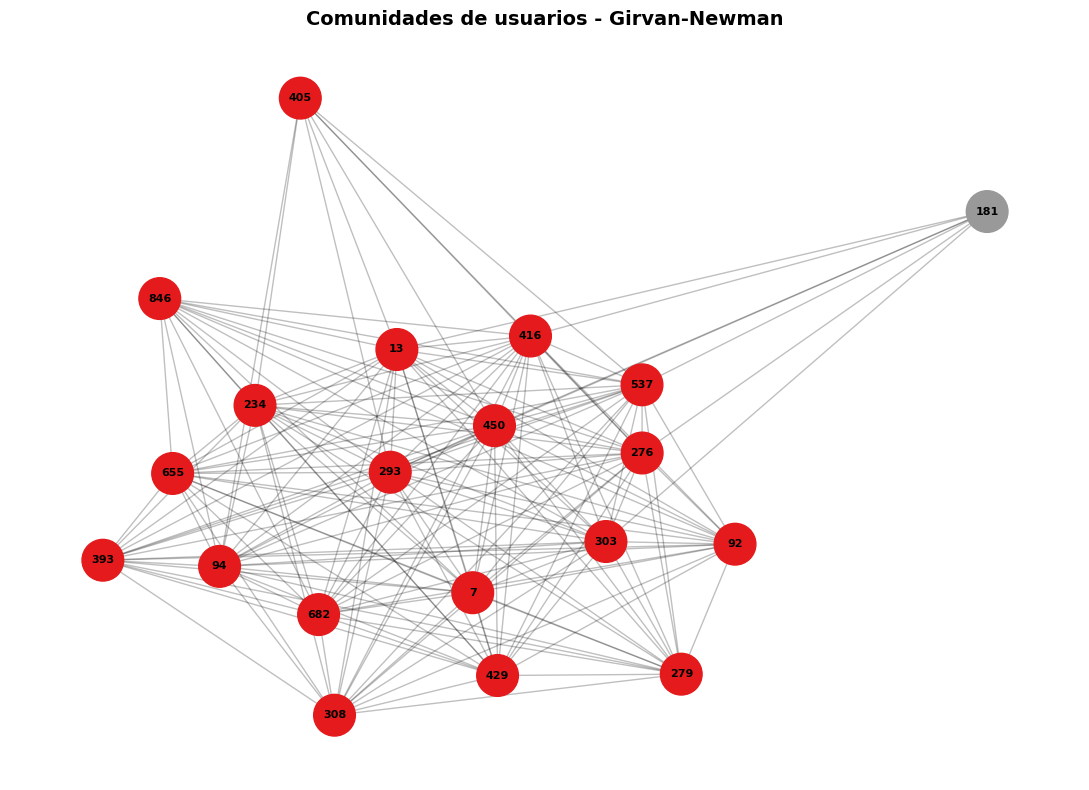

In [50]:
from networkx.algorithms.community import girvan_newman

# Obtener nuevamente la primera división
generador_visual = girvan_newman(G_comunidades)

division_visual = next(generador_visual)

comunidades_visual = [
    set(comunidad)
    for comunidad in division_visual
]

# Asignar una comunidad a cada usuario
comunidad_nodo = {}

for numero, comunidad in enumerate(comunidades_visual):
    for nodo in comunidad:
        comunidad_nodo[nodo] = numero

# Colores según comunidad
colores_nodos = [
    comunidad_nodo[nodo]
    for nodo in G_comunidades.nodes()
]

# Posición de los nodos
pos = nx.spring_layout(
    G_comunidades,
    seed=42,
    k=0.8
)

fig, ax = plt.subplots(figsize=(11, 8))

nx.draw_networkx_edges(
    G_comunidades,
    pos,
    ax=ax,
    alpha=0.25,
    width=1
)

nx.draw_networkx_nodes(
    G_comunidades,
    pos,
    node_color=colores_nodos,
    cmap=plt.cm.Set1,
    node_size=900,
    ax=ax
)

# Mostrar solamente el número del usuario
etiquetas = {
    nodo: nodo.replace("U_", "")
    for nodo in G_comunidades.nodes()
}

nx.draw_networkx_labels(
    G_comunidades,
    pos,
    labels=etiquetas,
    font_size=8,
    font_weight="bold",
    ax=ax
)

ax.set_title(
    "Comunidades de usuarios - Girvan-Newman",
    fontsize=14,
    fontweight="bold"
)

ax.axis("off")

plt.tight_layout()

fig.savefig(
    "comunidades_girvan_newman.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretación de la visualización de comunidades

La visualización muestra que la mayor parte de los usuarios pertenece a una única comunidad altamente conectada.

Girvan-Newman separa al usuario 181 como una comunidad independiente, mientras que los demás usuarios permanecen agrupados en un único conjunto principal.

Este comportamiento es consistente con los valores de modularidad obtenidos y confirma que la red analizada no presenta una estructura comunitaria fuertemente diferenciada.

# Parte 2 - Sistema de Recomendación con Surprise

En esta sección se implementarán modelos de recomendación colaborativa utilizando la librería `surprise`.

Se trabajará con el conjunto de datos MovieLens 100K para:

- preparar los datos en el formato requerido por Surprise;
- entrenar un modelo SVD;
- entrenar un modelo KNN;
- comparar su rendimiento mediante RMSE;
- ajustar hiperparámetros;
- generar recomendaciones de películas para un usuario específico.

In [52]:
%pip install scikit-surprise

   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.3 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.3 MB ? eta -:--:--
   ----------------------- ---------------- 0.8/1.3 MB 3.1 MB/s eta 0:00:01
   ---------------------------------------- 1.3/1.3 MB 3.6 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [53]:
try:
    import surprise
    print("Surprise está instalada correctamente")
except ImportError:
    print("Surprise no está instalada")

Surprise está instalada correctamente


## 2.2 Preparación de los datos para Surprise

Se adapta el conjunto de datos MovieLens 100K al formato requerido por la librería Surprise.

Para el sistema de recomendación se utilizan únicamente:

- identificador del usuario;
- identificador de la película;
- calificación otorgada.

La escala de calificación del dataset va de 1 a 5.

In [54]:
from surprise import Dataset, Reader

reader = Reader(
    rating_scale=(1, 5)
)

data_surprise = Dataset.load_from_df(
    ratings[
        ["user_id", "movie_id", "rating"]
    ],
    reader
)

print("Datos preparados correctamente para Surprise")

Datos preparados correctamente para Surprise


In [55]:
from surprise.model_selection import train_test_split

trainset, testset = train_test_split(
    data_surprise,
    test_size=0.20,
    random_state=42
)

print("Conjunto de entrenamiento creado")
print("Cantidad de calificaciones en prueba:", len(testset))

Conjunto de entrenamiento creado
Cantidad de calificaciones en prueba: 20000


## 2.3 Entrenamiento del modelo SVD

Se utiliza el algoritmo SVD (Singular Value Decomposition) para construir un sistema de recomendación colaborativa basado en factorización de matrices.

El modelo aprende patrones latentes a partir de las calificaciones realizadas por los usuarios y utiliza esta información para estimar calificaciones de películas no vistas.

In [56]:
from surprise import SVD
from surprise import accuracy

modelo_svd = SVD(
    random_state=42
)

modelo_svd.fit(trainset)

predicciones_svd = modelo_svd.test(testset)

rmse_svd = accuracy.rmse(
    predicciones_svd,
    verbose=True
)

RMSE: 0.9352


In [57]:
print(
    f"RMSE del modelo SVD: "
    f"{rmse_svd:.4f}"
)

RMSE del modelo SVD: 0.9352


## 2.4 Entrenamiento del modelo KNN

Se utiliza un modelo KNN basado en filtrado colaborativo para estimar las calificaciones a partir de usuarios con comportamientos similares.

En este caso se aplica una configuración usuario-usuario utilizando similitud coseno.

In [58]:
from surprise import KNNBasic

sim_options = {
    "name": "cosine",
    "user_based": True
}

modelo_knn = KNNBasic(
    k=40,
    sim_options=sim_options
)

modelo_knn.fit(trainset)

predicciones_knn = modelo_knn.test(testset)

rmse_knn = accuracy.rmse(
    predicciones_knn,
    verbose=True
)

Computing the cosine similarity matrix...
Done computing similarity matrix.
RMSE: 1.0194


In [59]:
print(
    f"RMSE del modelo KNN: "
    f"{rmse_knn:.4f}"
)

RMSE del modelo KNN: 1.0194


## 2.5 Comparación entre SVD y KNN

Se comparan los modelos SVD y KNN utilizando el RMSE como métrica de evaluación.

Un valor menor de RMSE indica una mayor precisión en la estimación de las calificaciones.

In [60]:
comparacion_modelos = pd.DataFrame({
    "Modelo": ["SVD", "KNN"],
    "RMSE": [rmse_svd, rmse_knn]
})

comparacion_modelos

,Modelo,RMSE
0,SVD,0.935171
1,KNN,1.019354


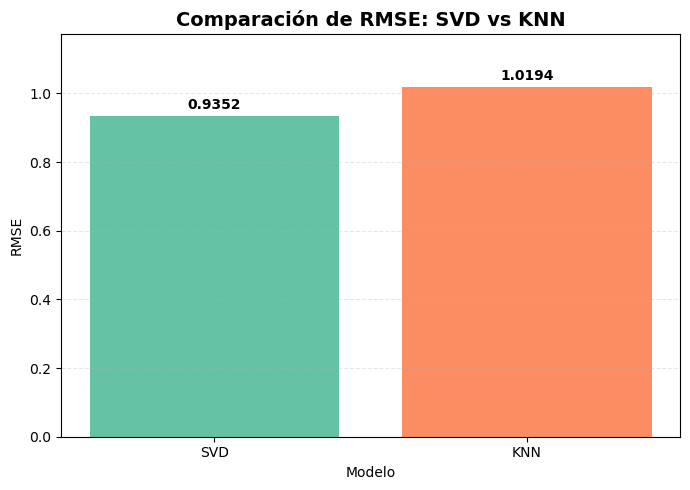

In [61]:
colores = plt.cm.Set2.colors

fig, ax = plt.subplots(figsize=(7, 5))

barras = ax.bar(
    comparacion_modelos["Modelo"],
    comparacion_modelos["RMSE"],
    color=colores[:2]
)

ax.set_title(
    "Comparación de RMSE: SVD vs KNN",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Modelo")
ax.set_ylabel("RMSE")

for barra in barras:
    valor = barra.get_height()

    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.01,
        f"{valor:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax.set_ylim(0, max(comparacion_modelos["RMSE"]) * 1.15)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

fig.savefig(
    "comparacion_rmse_svd_knn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretación

El modelo SVD obtuvo un RMSE de **0,9352**, mientras que KNN alcanzó un RMSE de **1,0194**.

Debido a que un menor RMSE representa un menor error de predicción, SVD presenta un mejor desempeño inicial para este conjunto de datos.

## 2.6 Ajuste de hiperparámetros

Se utiliza GridSearchCV para probar diferentes combinaciones de hiperparámetros y seleccionar la configuración que produzca el menor RMSE.

El objetivo es mejorar el rendimiento de los modelos de recomendación.

### 2.6.1 Optimización del modelo SVD

Se utiliza GridSearchCV para evaluar diferentes combinaciones de hiperparámetros del modelo SVD y seleccionar la configuración que produzca el menor RMSE.

In [62]:
from surprise.model_selection import GridSearchCV
from surprise import SVD

param_grid_svd = {
    "n_factors": [50, 100, 150],
    "n_epochs": [20, 30],
    "lr_all": [0.005, 0.01],
    "reg_all": [0.02, 0.05]
}

gs_svd = GridSearchCV(
    SVD,
    param_grid_svd,
    measures=["rmse"],
    cv=3,
    n_jobs=-1
)

gs_svd.fit(data_surprise)

print("Mejor RMSE SVD:", gs_svd.best_score["rmse"])
print("Mejores parámetros SVD:")
print(gs_svd.best_params["rmse"])

Mejor RMSE SVD: 0.9310477452030307
Mejores parámetros SVD:
{'n_factors': 50, 'n_epochs': 20, 'lr_all': 0.01, 'reg_all': 0.05}


### Interpretación del ajuste de SVD

La optimización mediante GridSearchCV permitió reducir el RMSE del modelo SVD de **0,9352** a aproximadamente **0,9310**.

Los mejores hiperparámetros encontrados fueron:

- `n_factors = 50`
- `n_epochs = 20`
- `lr_all = 0.01`
- `reg_all = 0.05`

Aunque la mejora es moderada, el modelo optimizado presenta un menor error de predicción que la configuración inicial.

### 2.6.2 Optimización del modelo KNN

Se prueban diferentes valores del número de vecinos y métricas de similitud para identificar la configuración que produzca el menor RMSE.

In [63]:
from surprise import KNNBasic

param_grid_knn = {
    "k": [20, 30, 40, 50],
    "sim_options": {
        "name": ["cosine", "msd", "pearson"],
        "user_based": [True, False]
    }
}

gs_knn = GridSearchCV(
    KNNBasic,
    param_grid_knn,
    measures=["rmse"],
    cv=3,
    n_jobs=-1
)

gs_knn.fit(data_surprise)

print("Mejor RMSE KNN:", gs_knn.best_score["rmse"])
print("Mejores parámetros KNN:")
print(gs_knn.best_params["rmse"])

Mejor RMSE KNN: 0.9863568731278739
Mejores parámetros KNN:
{'k': 40, 'sim_options': {'name': 'msd', 'user_based': False}}


### Interpretación del ajuste de KNN

La optimización mediante GridSearchCV permitió reducir el RMSE del modelo KNN de **1,0194** a aproximadamente **0,9864**.

La mejor configuración encontrada fue:

- `k = 40`
- similitud = `msd`
- `user_based = False`

Esto indica que, para este conjunto de datos, el enfoque ítem-ítem presentó un mejor desempeño que la configuración usuario-usuario utilizada inicialmente.

## 2.7 Comparación final de los modelos optimizados

Se comparan los mejores resultados obtenidos después del ajuste de hiperparámetros de los modelos SVD y KNN.

El modelo con menor RMSE será considerado el de mejor desempeño predictivo.

In [64]:
rmse_svd_optimizado = gs_svd.best_score["rmse"]
rmse_knn_optimizado = gs_knn.best_score["rmse"]

comparacion_optimizada = pd.DataFrame({
    "Modelo": [
        "SVD optimizado",
        "KNN optimizado"
    ],
    "RMSE": [
        rmse_svd_optimizado,
        rmse_knn_optimizado
    ]
})

comparacion_optimizada

,Modelo,RMSE
0,SVD optimizado,0.931048
1,KNN optimizado,0.986357


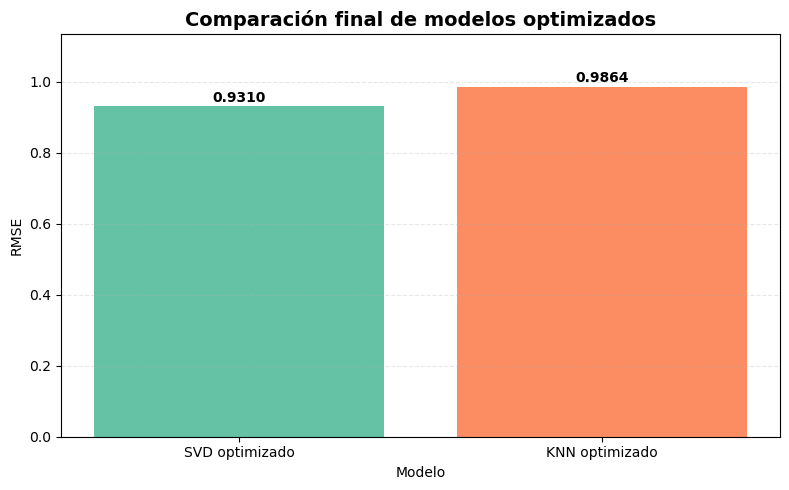

In [65]:
colores = plt.cm.Set2.colors

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    comparacion_optimizada["Modelo"],
    comparacion_optimizada["RMSE"],
    color=colores[:2]
)

ax.set_title(
    "Comparación final de modelos optimizados",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Modelo")
ax.set_ylabel("RMSE")

for barra in barras:
    valor = barra.get_height()

    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.005,
        f"{valor:.4f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax.set_ylim(
    0,
    max(comparacion_optimizada["RMSE"]) * 1.15
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

fig.savefig(
    "comparacion_modelos_optimizados.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretación de la comparación final

Después del ajuste de hiperparámetros, ambos modelos mejoraron su desempeño.

El modelo SVD optimizado obtuvo un RMSE de **0,9310**, mientras que el modelo KNN optimizado alcanzó un RMSE de **0,9864**.

Debido a que un menor RMSE representa un menor error de predicción, **SVD optimizado presenta el mejor desempeño** y será utilizado para generar las recomendaciones finales de películas.

## 2.8 Generación de recomendaciones de películas

Se utiliza el modelo SVD optimizado para generar recomendaciones personalizadas.

Para un usuario específico se identifican las películas que todavía no ha calificado y se estima la puntuación que podría otorgarles.

Finalmente, se seleccionan las cinco películas con mayor calificación estimada.

In [66]:
mejores_parametros_svd = gs_svd.best_params["rmse"]

modelo_svd_final = SVD(
    **mejores_parametros_svd,
    random_state=42
)

trainset_completo = data_surprise.build_full_trainset()

modelo_svd_final.fit(trainset_completo)

print("Modelo SVD optimizado entrenado con todo el dataset")

Modelo SVD optimizado entrenado con todo el dataset


### 2.8.1 Selección del usuario

Para demostrar el funcionamiento del sistema de recomendación se selecciona al usuario **405**.

Se identificarán las películas que todavía no ha calificado y se estimará la puntuación que podría otorgarles mediante el modelo SVD optimizado.

In [67]:
usuario_objetivo = 405

peliculas_vistas = set(
    ratings[
        ratings["user_id"] == usuario_objetivo
    ]["movie_id"]
)

print("Usuario seleccionado:", usuario_objetivo)
print("Películas calificadas:", len(peliculas_vistas))

Usuario seleccionado: 405
Películas calificadas: 737


### 2.8.2 Identificación de películas no calificadas

Se identifican las películas que todavía no han sido calificadas por el usuario seleccionado.

Estas películas constituyen el conjunto de opciones sobre las cuales el modelo realizará las predicciones.

In [68]:
todas_peliculas = set(
    movies["movie_id"]
)

peliculas_no_vistas = (
    todas_peliculas - peliculas_vistas
)

print(
    "Películas no calificadas:",
    len(peliculas_no_vistas)
)

Películas no calificadas: 945


### 2.8.3 Predicción de calificaciones

El modelo SVD optimizado estima la calificación que el usuario podría otorgar a cada una de las películas que todavía no ha evaluado.

Estas puntuaciones estimadas se utilizan para ordenar las posibles recomendaciones.

In [69]:
recomendaciones = []

for movie_id in peliculas_no_vistas:

    prediccion = modelo_svd_final.predict(
        usuario_objetivo,
        movie_id
    )

    recomendaciones.append({
        "movie_id": movie_id,
        "rating_estimado": prediccion.est
    })

recomendaciones = pd.DataFrame(
    recomendaciones
)

recomendaciones.head()

,movie_id,rating_estimado
0,1,2.682922
1,3,1.400744
2,6,2.442155
3,7,1.936290
4,9,1.992820


### 2.8.4 Selección de las cinco mejores recomendaciones

Las películas se ordenan según la calificación estimada por el modelo.

Se seleccionan las cinco películas con mayor puntuación prevista para conformar las recomendaciones finales del usuario.

In [70]:
recomendaciones = recomendaciones.merge(
    movies,
    on="movie_id",
    how="left"
)

top_5_recomendaciones = (
    recomendaciones
    .sort_values(
        "rating_estimado",
        ascending=False
    )
    .head(5)
)

top_5_recomendaciones[
    [
        "movie_id",
        "title",
        "rating_estimado"
    ]
]

,movie_id,title,rating_estimado
238,496,It's a Wonderful Life (1946),4.010096
54,144,Die Hard (1988),3.813702
126,283,Emma (1996),3.244375
60,151,Willy Wonka and the Chocolate Factory (1971),3.146174
582,1142,When We Were Kings (1996),3.051733


### 2.8.5 Visualización de las recomendaciones

Se presentan gráficamente las cinco películas con mayor calificación estimada para el usuario seleccionado.

Las puntuaciones corresponden a las predicciones generadas por el modelo SVD optimizado.

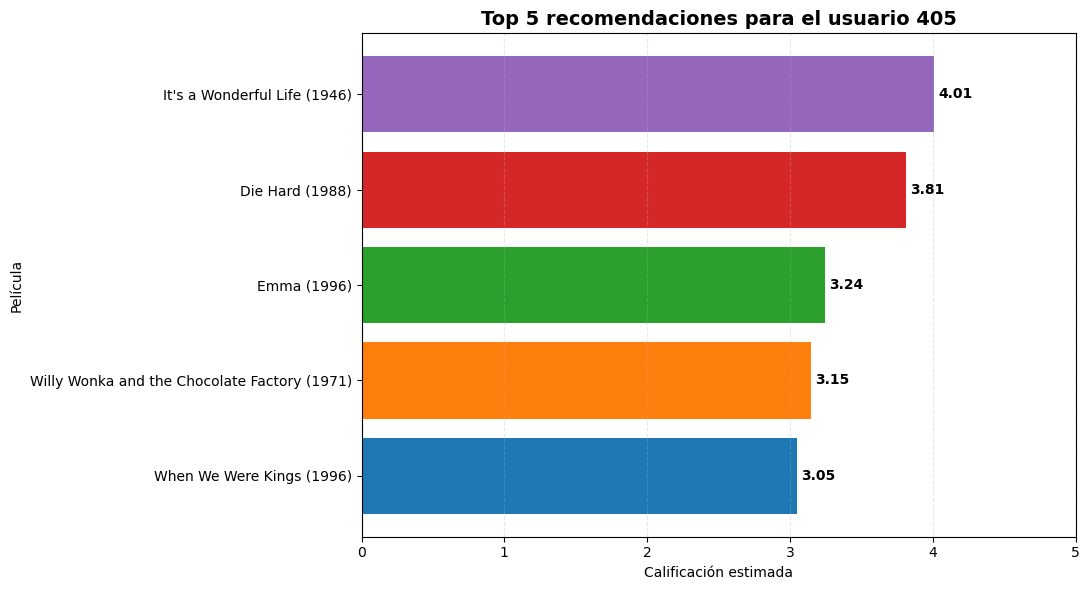

In [71]:
datos_recomendaciones = (
    top_5_recomendaciones
    .sort_values("rating_estimado")
)

colores = plt.cm.tab10.colors

fig, ax = plt.subplots(figsize=(11, 6))

barras = ax.barh(
    datos_recomendaciones["title"],
    datos_recomendaciones["rating_estimado"],
    color=colores[:5]
)

ax.set_title(
    "Top 5 recomendaciones para el usuario 405",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Calificación estimada")
ax.set_ylabel("Película")

for barra in barras:
    valor = barra.get_width()

    ax.text(
        valor + 0.03,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.2f}",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

ax.set_xlim(0, 5)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

fig.savefig(
    "top_5_recomendaciones_usuario_405.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretación

El modelo SVD optimizado recomienda principalmente **It's a Wonderful Life (1946)** y **Die Hard (1988)** para el usuario 405, con calificaciones estimadas superiores a las demás opciones.

La mayor puntuación estimada corresponde a **It's a Wonderful Life (1946)** con aproximadamente **4,01 puntos sobre 5**.

Estas recomendaciones fueron generadas únicamente entre películas que el usuario no había calificado previamente.

## 2.9 Conclusión del sistema de recomendación

Los resultados obtenidos muestran que el modelo SVD presentó un mejor desempeño que KNN tanto en su configuración inicial como después del ajuste de hiperparámetros.

El modelo SVD optimizado alcanzó un RMSE aproximado de **0,9310**, mientras que KNN optimizado obtuvo un RMSE de **0,9864**.

Debido a su menor error de predicción, SVD fue seleccionado como el modelo final para generar recomendaciones personalizadas.

Para el usuario 405, el sistema recomendó cinco películas que no habían sido calificadas previamente, destacándose **It's a Wonderful Life (1946)** con una calificación estimada de aproximadamente **4,01 sobre 5**.

Estos resultados muestran que el filtrado colaborativo puede utilizar patrones históricos de calificaciones para generar recomendaciones personalizadas de películas.

# Conclusiones generales del Taller 03

El desarrollo del taller permitió aplicar técnicas de análisis de redes y sistemas de recomendación sobre el conjunto de datos MovieLens 100K.

En la primera parte se construyó un grafo bipartito con **2.625 nodos** y **100.000 aristas**, representando las relaciones entre usuarios y películas.

El análisis permitió identificar a los usuarios más activos y a las películas con mayor centralidad dentro de la red. **Star Wars (1977)** presentó el mayor número de conexiones entre las películas analizadas.

También se estudió el coeficiente de agrupamiento y se aplicaron métodos de detección de comunidades. Los resultados de Girvan-Newman y Greedy Modularity evidenciaron que la subred de usuarios más activos presenta una estructura altamente conectada y sin comunidades claramente diferenciadas.

En la segunda parte se implementaron modelos de recomendación colaborativa utilizando SVD y KNN.

El modelo SVD presentó un mejor desempeño y, después del ajuste de hiperparámetros, alcanzó un RMSE aproximado de **0,9310**, frente al **0,9864** obtenido por KNN optimizado.

Finalmente, el modelo SVD optimizado permitió generar recomendaciones personalizadas para un usuario específico, demostrando la utilidad de los sistemas de recomendación para estimar preferencias a partir del comportamiento histórico de los usuarios.